# Classificador de pássaros do Cerrado: ViT-H/14

Faculdade de Ciências e Tecnologias em Engenharia - Campus UnB Gama <br>
Tópicos Especiais em Matemática Aplicada: Deep Learning <br>
Professor: Vinicius Rispoli<br>
Alunos: Eliseu Kadesh, Pedro Barbosa e Raquel Eucaria.

Notebook principal: prepara os dados, treina a CNN do zero e o ViT-H/14 e avalia os dois. Contexto, resultados comparados e limitações estão no [README](../README.md).

Executado no Colab com GPU A100 e RAM alta. Os dados devem estar em `data/passaros` (veja a seção [Dataset](../README.md#dataset) do README).

## 1. Dados

### Configuração

Importações, caminhos e hiperparâmetros. Antes do treino, foram removidas do dataset as pastas de metadados do macOS.

In [ ]:
import os
import shutil
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from torch import nn, optim # PyTorch
from torch.utils.data import DataLoader
from torch.cuda.amp import GradScaler
from torchvision import datasets, transforms, models # Torchvision
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay # Scikit-learn

MAIN_DIR = "data/passaros"  # raiz local dos dados; veja a seção Dataset do README
SOURCE_DATA_DIR = os.path.join(MAIN_DIR, "dataset")
SPLIT_DATA_DIR = os.path.join(MAIN_DIR, "dataset_split")


IMG_SIZE = 224
BATCH_SIZE = 128
LEARNING_RATE_CNN = 1e-3
LEARNING_RATE_TL = 1e-3
LEARNING_RATE_FT = 1e-5 # LR baixo é crucial para fine-tuning
EPOCHS_SCRATCH = 15
EPOCHS_TL = 10
EPOCHS_FT = 15


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_COMPILE = hasattr(torch, 'compile') and torch.__version__.startswith('2')
print(f"Dispositivo de execução: {DEVICE}")
print(f"torch.compile() será utilizado: {USE_COMPILE}")

Dispositivo de execução: cuda
torch.compile() será utilizado: True


### Divisão treino/validação/teste

Holdout 80/10/10 por espécie, gravado em `dataset_split`.

In [ ]:
def split_dataset(source_dir, base_dir, split_ratio=(0.8, 0.1, 0.1)):
    """Divide o dataset de imagens em pastas de treino, validação e teste."""
    os.makedirs(MAIN_DIR, exist_ok=True)
    if os.path.exists(base_dir):
        print(f"Diretório '{base_dir}' já existe. Divisão não será executada.")
        return
    if not os.path.exists(source_dir):
        print(f"ERRO: Diretório de origem '{source_dir}' não encontrado.")
        return
    print(f"Criando nova estrutura de pastas em '{base_dir}'...")

    train_dir = os.path.join(base_dir, 'train')
    val_dir = os.path.join(base_dir, 'val')
    test_dir = os.path.join(base_dir, 'test')
    os.makedirs(train_dir); os.makedirs(val_dir); os.makedirs(test_dir)
    species = [s for s in os.listdir(source_dir) if os.path.isdir(os.path.join(source_dir, s))]

    for s in species:
        print(f"Processando espécie: {s}")
        os.makedirs(os.path.join(train_dir, s), exist_ok=True)
        os.makedirs(os.path.join(val_dir, s), exist_ok=True)
        os.makedirs(os.path.join(test_dir, s), exist_ok=True)

        src_species_dir = os.path.join(source_dir, s)
        images = [f for f in os.listdir(src_species_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        random.shuffle(images)

        train_idx = int(len(images) * split_ratio[0])
        val_idx = int(len(images) * (split_ratio[0] + split_ratio[1]))

        train_files, val_files, test_files = images[:train_idx], images[train_idx:val_idx], images[val_idx:]

        for f in train_files: shutil.copy(os.path.join(src_species_dir, f), os.path.join(train_dir, s, f))
        for f in val_files: shutil.copy(os.path.join(src_species_dir, f), os.path.join(val_dir, s, f))
        for f in test_files: shutil.copy(os.path.join(src_species_dir, f), os.path.join(test_dir, s, f))

    print("\nDivisão do dataset concluída com sucesso!")

split_dataset(SOURCE_DATA_DIR, SPLIT_DATA_DIR)

Diretório 'data/passaros/dataset_split' já existe. Divisão não será executada.


### Classes

In [ ]:
train_dir = os.path.join(SPLIT_DATA_DIR, 'train')

simple_transform = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor()])
display_dataset = datasets.ImageFolder(root=train_dir, transform=simple_transform)
display_loader = DataLoader(display_dataset, batch_size=25, shuffle=True)

images, labels = next(iter(display_loader))
class_names = display_dataset.classes

classes = sorted(os.listdir(train_dir))
num_classes = len(classes)
print(f"\nEncontradas {num_classes} classes: {classes}")


Encontradas 14 classes: ['amazona_aestiva', 'amazona_amazonica', 'anodorhynchus_hyacinthinus', 'ara_ararauna', 'ara_chloropterus', 'ara_macao', 'brotogeris_chiriri', 'diopsittaca_nobilis', 'eupsittula_aurea', 'forpus_xanthopterygius', 'orthopsittaca_manilatus', 'primolius_maracana', 'psittacara_leucophthalmus', 'touit_melanonotus']


### Pré-processamento

In [ ]:
val_dir = os.path.join(SPLIT_DATA_DIR, 'val')
test_dir = os.path.join(SPLIT_DATA_DIR, 'test')

# Normalização padrão da ImageNet
imagenet_mean = [0.485, 0.456, 0.406]; imagenet_std = [0.229, 0.224, 0.225]

### Data augmentation e DataLoaders

Augmentation aplicada só ao treino.

In [ ]:
transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])
transform_val_test = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

train_dataset = datasets.ImageFolder(train_dir, transform=transform_train)
val_dataset = datasets.ImageFolder(val_dir, transform=transform_val_test)
test_dataset = datasets.ImageFolder(test_dir, transform=transform_val_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Tamanho do dataset de treino: {len(train_dataset)} imagens")
print(f"Tamanho do dataset de validação: {len(val_dataset)} imagens")
print(f"Tamanho do dataset de teste: {len(test_dataset)} imagens")


Tamanho do dataset de treino: 2425 imagens
Tamanho do dataset de validação: 304 imagens
Tamanho do dataset de teste: 308 imagens


## 2. Treino

### Funções de treino e avaliação

Treino com precisão mista (AMP).

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, desc='Treino (AMP)', leave=False)
    for inputs, targets in pbar:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast():
            outputs = model(inputs)
            loss = criterion(outputs, targets)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0); correct += predicted.eq(targets).sum().item()
        pbar.set_postfix({'loss': running_loss/total, 'acc': f"{100.*correct/total:.2f}%"})
    return running_loss/total, 100.*correct/total

def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        pbar = tqdm(loader, desc='Validação', leave=False)
        for inputs, targets in pbar:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            with torch.cuda.amp.autocast():
                outputs = model(inputs)
                loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0); correct += predicted.eq(targets).sum().item()
            pbar.set_postfix({'loss': running_loss/total, 'acc': f"{100.*correct/total:.2f}%"})
    return running_loss/total, 100.*correct/total

def get_predictions(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in tqdm(loader, "Gerando previsões no conjunto de teste"):
            inputs = inputs.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy()); all_labels.extend(labels.cpu().numpy())
    return np.array(all_labels), np.array(all_preds)

def plot_confusion_matrix(labels, preds, class_names, title):
    cm = confusion_matrix(labels, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(12, 12))
    disp.plot(ax=ax, xticks_rotation='vertical', cmap='viridis')
    ax.set_title(title, fontsize=15); plt.tight_layout(); plt.show()

### CNN do zero (linha de base)

Três blocos de convolução e pooling e duas camadas densas.

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, 1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, 1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, 1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 26 * 26, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))

cnn_scratch = SimpleCNN(len(class_names)).to(DEVICE)
criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = optim.Adam(cnn_scratch.parameters(), lr=LEARNING_RATE_CNN)
scaler_cnn = GradScaler()

print("\n--- ETAPA 3: INICIANDO TREINAMENTO DA CNN DO ZERO ---")
for epoch in range(EPOCHS_SCRATCH):
    print(f"\nÉpoca {epoch+1}/{EPOCHS_SCRATCH}")
    train_loss, train_acc = train_one_epoch(cnn_scratch, train_loader, criterion_cnn, optimizer_cnn, scaler_cnn)
    val_loss, val_acc = evaluate(cnn_scratch, val_loader, criterion_cnn)
    print(f"  Loss Treino: {train_loss:.4f}, Acc Treino: {train_acc:.2f}% | Loss Val: {val_loss:.4f}, Acc Val: {val_acc:.2f}%")


--- ETAPA 3: INICIANDO TREINAMENTO DA CNN DO ZERO ---

Época 1/15
  Loss Treino: 21.5745, Acc Treino: 8.45% | Loss Val: 2.6932, Acc Val: 8.88%

Época 2/15
  Loss Treino: 2.6559, Acc Treino: 7.05% | Loss Val: 2.6280, Acc Val: 8.88%

Época 3/15
  Loss Treino: 2.6257, Acc Treino: 7.51% | Loss Val: 2.6174, Acc Val: 9.54%

Época 4/15
  Loss Treino: 2.6225, Acc Treino: 7.63% | Loss Val: 2.6073, Acc Val: 11.51%

Época 5/15
  Loss Treino: 2.6161, Acc Treino: 8.70% | Loss Val: 2.5934, Acc Val: 12.17%

Época 6/15
  Loss Treino: 2.6002, Acc Treino: 9.53% | Loss Val: 2.5638, Acc Val: 12.83%

Época 7/15
  Loss Treino: 2.5866, Acc Treino: 10.31% | Loss Val: 2.5417, Acc Val: 9.87%

Época 8/15
  Loss Treino: 2.5634, Acc Treino: 11.67% | Loss Val: 2.4803, Acc Val: 17.11%

Época 9/15
  Loss Treino: 2.5212, Acc Treino: 12.70% | Loss Val: 2.4409, Acc Val: 17.11%

Época 10/15
  Loss Treino: 2.5187, Acc Treino: 12.12% | Loss Val: 2.4222, Acc Val: 15.46%

Época 11/15
  Loss Treino: 2.5007, Acc Treino: 11.46

### ViT-H/14: extração de características

Pesos SWAG congelados; só o novo classificador de 14 classes é treinado, por 10 épocas. Os experimentos com ResNet-18 e ViT-B/16 estão nos notebooks [02](02_anexo_resnet18.ipynb) e [03](03_anexo_vit_b16.ipynb).

In [ ]:
print("\n--- ETAPA 4: TRANSFER LEARNING (FEATURE EXTRACTION) ---")
model_vit = models.vit_h_14(weights=models.ViT_H_14_Weights.IMAGENET1K_SWAG_LINEAR_V1)
for param in model_vit.parameters(): param.requires_grad = False
model_vit.heads.head = nn.Linear(model_vit.heads.head.in_features, len(class_names))
if USE_COMPILE: model_vit = torch.compile(model_vit)
model_vit = model_vit.to(DEVICE)
criterion_vit = nn.CrossEntropyLoss()
optimizer_vit = optim.Adam(model_vit.heads.head.parameters(), lr=LEARNING_RATE_TL)
scaler_vit = GradScaler()

for epoch in range(EPOCHS_TL):
    print(f"\nÉpoca {epoch+1}/{EPOCHS_TL}")
    train_loss, train_acc = train_one_epoch(model_vit, train_loader, criterion_vit, optimizer_vit, scaler_vit)
    val_loss, val_acc = evaluate(model_vit, val_loader, criterion_vit)
    print(f"  Loss Treino: {train_loss:.4f}, Acc Treino: {train_acc:.2f}% | Loss Val: {val_loss:.4f}, Acc Val: {val_acc:.2f}%")


--- ETAPA 4: TRANSFER LEARNING (FEATURE EXTRACTION) ---

Época 1/10
  Loss Treino: 1.9864, Acc Treino: 36.25% | Loss Val: 1.4786, Acc Val: 54.61%

Época 2/10
  Loss Treino: 1.2183, Acc Treino: 64.08% | Loss Val: 1.1406, Acc Val: 61.84%

Época 3/10
  Loss Treino: 0.9608, Acc Treino: 71.71% | Loss Val: 0.9487, Acc Val: 69.74%

Época 4/10
  Loss Treino: 0.8304, Acc Treino: 76.04% | Loss Val: 0.8692, Acc Val: 72.70%

Época 5/10
  Loss Treino: 0.7276, Acc Treino: 80.25% | Loss Val: 0.8325, Acc Val: 71.38%

Época 6/10
  Loss Treino: 0.6703, Acc Treino: 81.28% | Loss Val: 0.7551, Acc Val: 75.66%

Época 7/10
  Loss Treino: 0.6130, Acc Treino: 83.01% | Loss Val: 0.7334, Acc Val: 75.66%

Época 8/10
  Loss Treino: 0.5824, Acc Treino: 83.84% | Loss Val: 0.6845, Acc Val: 77.30%

Época 9/10
  Loss Treino: 0.5543, Acc Treino: 84.37% | Loss Val: 0.6536, Acc Val: 78.62%

Época 10/10
  Loss Treino: 0.5006, Acc Treino: 86.97% | Loss Val: 0.6377, Acc Val: 77.30%


### ViT-H/14: fine-tuning

Rede inteira descongelada, lr 1e-5, 15 épocas.

In [ ]:
for param in model_vit.parameters(): param.requires_grad = True
optimizer_vit = optim.Adam(model_vit.parameters(), lr=LEARNING_RATE_FT)

for epoch in range(EPOCHS_FT):
    print(f"\nÉpoca {epoch+1}/{EPOCHS_FT}")
    train_loss, train_acc = train_one_epoch(model_vit, train_loader, criterion_vit, optimizer_vit, scaler_vit)
    val_loss, val_acc = evaluate(model_vit, val_loader, criterion_vit)
    print(f"  Loss Treino: {train_loss:.4f}, Acc Treino: {train_acc:.2f}% | Loss Val: {val_loss:.4f}, Acc Val: {val_acc:.2f}%")


Época 1/15
  Loss Treino: 0.3929, Acc Treino: 86.93% | Loss Val: 0.2490, Acc Val: 91.45%

Época 2/15
  Loss Treino: 0.1294, Acc Treino: 96.25% | Loss Val: 0.1846, Acc Val: 92.76%

Época 3/15
  Loss Treino: 0.0590, Acc Treino: 98.31% | Loss Val: 0.1555, Acc Val: 95.39%

Época 4/15
  Loss Treino: 0.0305, Acc Treino: 99.55% | Loss Val: 0.1545, Acc Val: 94.41%

Época 5/15
  Loss Treino: 0.0186, Acc Treino: 99.79% | Loss Val: 0.1262, Acc Val: 95.07%

Época 6/15
  Loss Treino: 0.0225, Acc Treino: 99.26% | Loss Val: 0.1527, Acc Val: 94.41%

Época 7/15
  Loss Treino: 0.0255, Acc Treino: 99.42% | Loss Val: 0.1678, Acc Val: 94.08%

Época 8/15
  Loss Treino: 0.0116, Acc Treino: 99.75% | Loss Val: 0.1518, Acc Val: 95.07%

Época 9/15
  Loss Treino: 0.0119, Acc Treino: 99.75% | Loss Val: 0.1590, Acc Val: 94.08%

Época 10/15
  Loss Treino: 0.0142, Acc Treino: 99.63% | Loss Val: 0.1828, Acc Val: 93.75%

Época 11/15
  Loss Treino: 0.0123, Acc Treino: 99.59% | Loss Val: 0.2004, Acc Val: 93.09%

Época 1

## 3. Avaliação

### Teste interno (308 imagens)


--- ETAPA 6: ANÁLISE E COMPARAÇÃO DOS RESULTADOS ---

                    AVALIAÇÃO FINAL - CNN CONSTRUÍDA DO ZERO

Relatório de Classificação (CNN do Zero):
                            precision    recall  f1-score   support

           amazona_aestiva     0.0000    0.0000    0.0000        25
         amazona_amazonica     0.0000    0.0000    0.0000        21
anodorhynchus_hyacinthinus     0.5000    0.6000    0.5455        25
              ara_ararauna     0.1053    0.0800    0.0909        25
          ara_chloropterus     0.4500    0.4091    0.4286        22
                 ara_macao     0.1667    0.0909    0.1176        22
        brotogeris_chiriri     0.0000    0.0000    0.0000        20
       diopsittaca_nobilis     0.0893    0.8333    0.1613        24
          eupsittula_aurea     0.0000    0.0000    0.0000        22
    forpus_xanthopterygius     0.0000    0.0000    0.0000        22
   orthopsittaca_manilatus     0.0000    0.0000    0.0000        20
        primolius_maraca

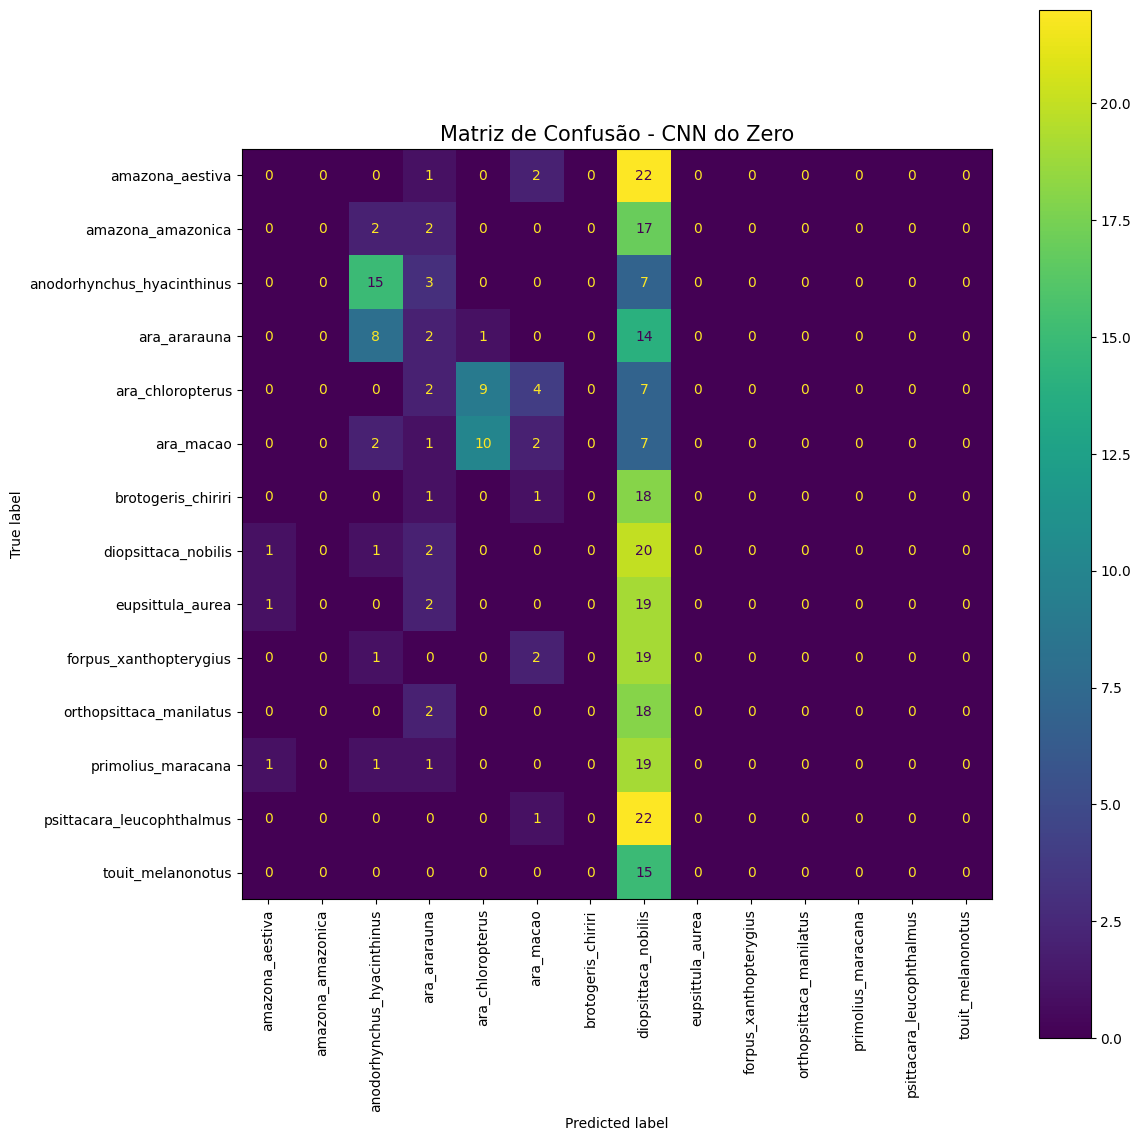

In [ ]:
print("\n--- ETAPA 6: ANÁLISE E COMPARAÇÃO DOS RESULTADOS ---")
# --- Análise do Modelo CNN do Zero ---
print("\n" + "="*80)
print(" " * 20 + "AVALIAÇÃO FINAL - CNN CONSTRUÍDA DO ZERO")
print("="*80)
labels_cnn, preds_cnn = get_predictions(cnn_scratch, test_loader)
print("\nRelatório de Classificação (CNN do Zero):")
print(classification_report(labels_cnn, preds_cnn, target_names=class_names, digits=4))
plot_confusion_matrix(labels_cnn, preds_cnn, class_names, 'Matriz de Confusão - CNN do Zero')


                  AVALIAÇÃO FINAL - ViT-H/14 COM FINE-TUNING

Relatório de Classificação (ViT-H/14 Fine-Tuned):
                            precision    recall  f1-score   support

           amazona_aestiva     0.9583    0.9200    0.9388        25
         amazona_amazonica     0.9524    0.9524    0.9524        21
anodorhynchus_hyacinthinus     1.0000    1.0000    1.0000        25
              ara_ararauna     0.9600    0.9600    0.9600        25
          ara_chloropterus     0.9545    0.9545    0.9545        22
                 ara_macao     0.9545    0.9545    0.9545        22
        brotogeris_chiriri     0.7917    0.9500    0.8636        20
       diopsittaca_nobilis     0.9091    0.8333    0.8696        24
          eupsittula_aurea     0.9500    0.8636    0.9048        22
    forpus_xanthopterygius     0.8148    1.0000    0.8980        22
   orthopsittaca_manilatus     0.8000    1.0000    0.8889        20
        primolius_maracana     0.9474    0.8182    0.8780        22
 p

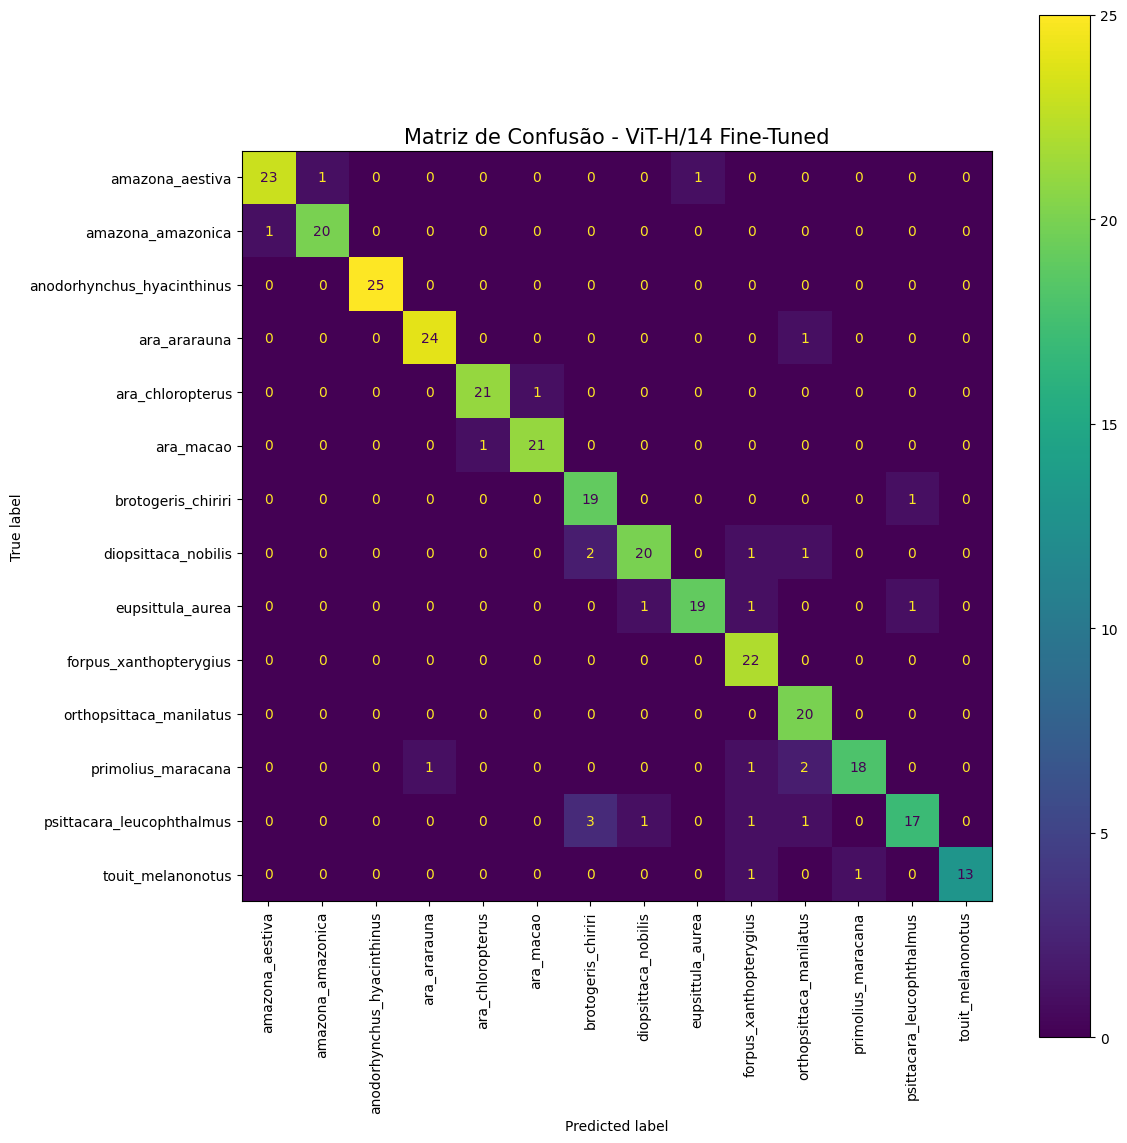

In [ ]:
# --- Análise do Modelo ViT-H/14 com Fine-Tuning ---
print("\n" + "="*80)
print(" " * 18 + "AVALIAÇÃO FINAL - ViT-H/14 COM FINE-TUNING")
print("="*80)
model_to_eval = model_vit._orig_mod if USE_COMPILE and hasattr(model_vit, '_orig_mod') else model_vit
labels_vit, preds_vit = get_predictions(model_to_eval, test_loader)
print("\nRelatório de Classificação (ViT-H/14 Fine-Tuned):")
print(classification_report(labels_vit, preds_vit, target_names=class_names, digits=4))
plot_confusion_matrix(labels_vit, preds_vit, class_names, 'Matriz de Confusão - ViT-H/14 Fine-Tuned')

### Base final do professor (113 imagens)

Base separada, fornecida pelo professor, que não foi usada no treino nem na validação.


--- AVALIAÇÃO FINAL COM DADOS EXTERNOS ---
Carregando a base de dados de teste final de: data/passaros/Aves_teste_final

Encontradas 113 imagens no diretório de teste final.
Classes identificadas: ['amazona_aestiva', 'amazona_amazonica', 'anodorhynchus_hyacinthinus', 'ara_ararauna', 'ara_chloropterus', 'ara_macao', 'brotogeris_chiriri', 'diopsittaca_nobilis', 'eupsittula_aurea', 'forpus_xanthopterygius', 'orthopsittaca_manilatus', 'primolius_maracana', 'psittacara_leucophthalmus', 'touit_melanonotus']

--- GERANDO PREVISÕES NO CONJUNTO DE TESTE FINAL ---

>>> Acurácia Final no Teste Externo: 97.35%

Relatório de Classificação Detalhado (Teste Final):
                            precision    recall  f1-score   support

           amazona_aestiva     0.8889    1.0000    0.9412         8
         amazona_amazonica     1.0000    0.8750    0.9333         8
anodorhynchus_hyacinthinus     1.0000    1.0000    1.0000         8
              ara_ararauna     1.0000    1.0000    1.0000         8

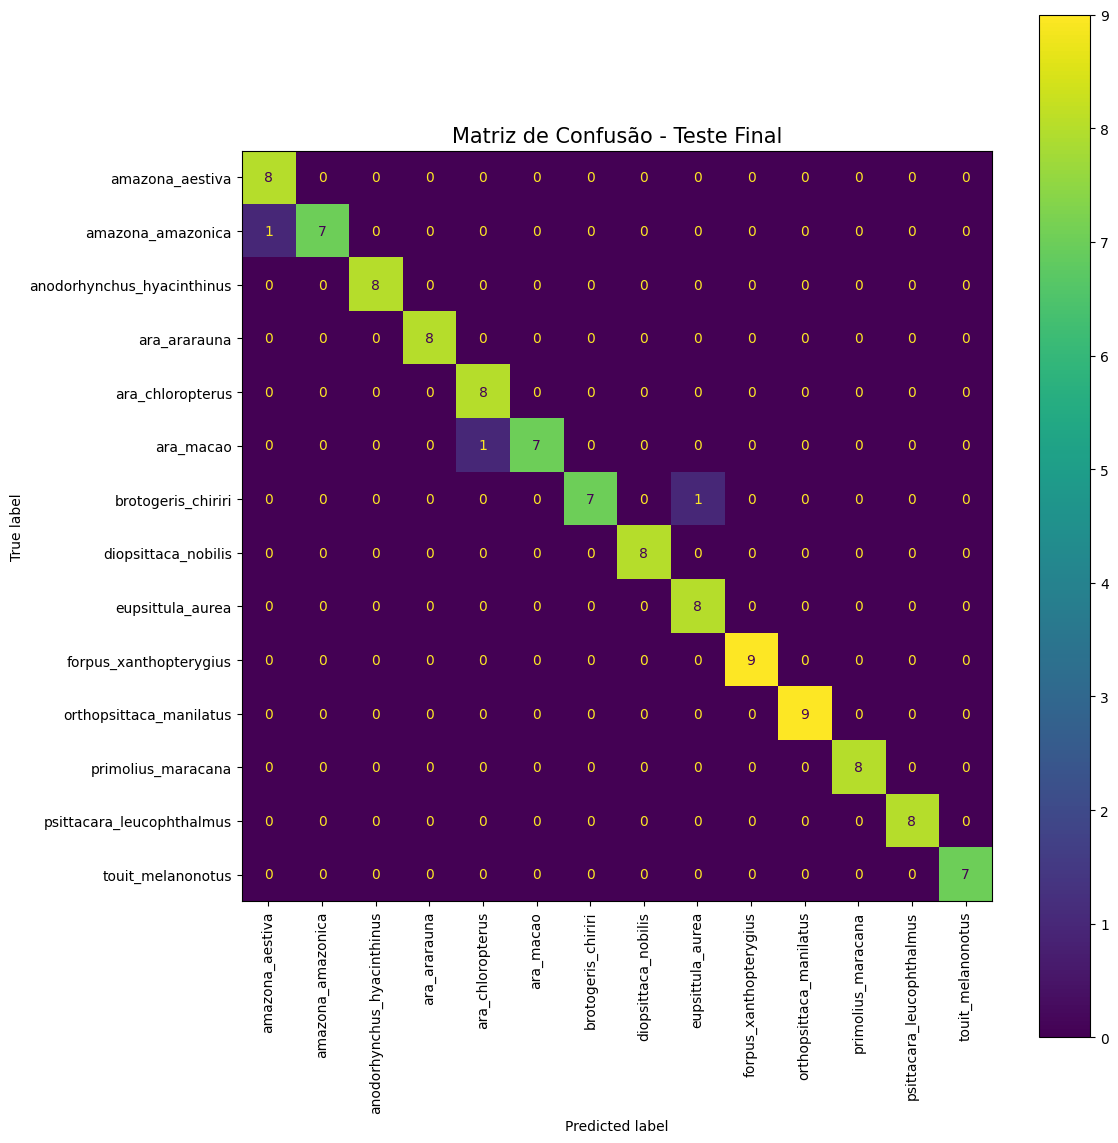

In [ ]:
from sklearn.metrics import accuracy_score

print("\n--- AVALIAÇÃO FINAL COM DADOS EXTERNOS ---")

# --- Caminho para base de teste final ---
TESTE_FINAL_DIR = "data/passaros/Aves_teste_final"
print(f"Carregando a base de dados de teste final de: {TESTE_FINAL_DIR}")

try:
    teste_final_dataset = datasets.ImageFolder(root=TESTE_FINAL_DIR, transform=transform_val_test)
    test_final_loader = DataLoader(teste_final_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    print(f"\nEncontradas {len(teste_final_dataset)} imagens no diretório de teste final.")
    print(f"Classes identificadas: {teste_final_dataset.classes}\n")

    # Usa o modelo e a função de predição
    print("--- GERANDO PREVISÕES NO CONJUNTO DE TESTE FINAL ---")
    final_model_to_eval = model_vit._orig_mod if USE_COMPILE and hasattr(model_vit, '_orig_mod') else model_vit
    y_true_final, y_pred_final = get_predictions(final_model_to_eval, test_final_loader)

    # Exibe os resultados
    final_class_names = teste_final_dataset.classes


    final_accuracy = accuracy_score(y_true_final, y_pred_final)
    print(f"\n\033[1m>>> Acurácia Final no Teste Externo: {final_accuracy:.2%}\033[0m\n") # Em negrito e como porcentagem
    # -------------------------------

    print("Relatório de Classificação Detalhado (Teste Final):")
    print(classification_report(y_true_final, y_pred_final, target_names=final_class_names, digits=4, zero_division=0))

    plot_confusion_matrix(y_true_final, y_pred_final, final_class_names, 'Matriz de Confusão - Teste Final')

except FileNotFoundError:
    print(f"\nERRO: O diretório de teste não foi encontrado em '{TESTE_FINAL_DIR}'")
    print("Por favor, verifique se o caminho para a pasta 'Aves_teste_final' está correto.")
except NameError as e:
    print(f"\nERRO: Uma variável essencial não foi definida: {e}")
    print("Isso geralmente acontece quando as células não são executadas em ordem. Por favor, use 'Ambiente de execução > Reiniciar e executar tudo'.")

## Resultados

A comparação entre os modelos, o que aprendemos e as limitações estão no [README](../README.md#resultados).